In [34]:
# Chit 14: CIFAR-10 FNN: ten object categories
# Step 1: Import the libraries
import numpy as np
import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Input, Dense
import pandas as pd
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt

In [43]:
# Step 2: Load and prepare CIFAR-10
data = pd.read_csv("cifar-10.csv", dtype=np.uint8)

y = data["label"].to_numpy(dtype="int64")
X = data.drop(columns="label").to_numpy(dtype="float32")

X = X.reshape(-1, 3, 32, 32).transpose(0, 2, 3, 1) / 255.0

class_names = ["airplane", "automobile", "bird", "cat", "deer", "dog", "frog", "horse", "ship", "truck"]

image_shape = (32, 32, 3)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42
)

In [44]:
# Step 3: Flatten the images
X_train = X_train.reshape(len(X_train), 3072)
X_test = X_test.reshape(len(X_test), 3072)

In [45]:
# Step 4: Build the model
num_classes = len(class_names)
model = Sequential([
    Input(shape=(X_train.shape[1],)),
    Dense(256, activation="relu"),
    Dense(128, activation="relu"),
    Dense(num_classes, activation="softmax")
])

In [46]:
# Step 5: Compile and train
model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

In [47]:
# Step 6: Prepare and run the model
model.fit(X_train, y_train, epochs=15, batch_size=128, verbose=0)

In [48]:
# Step 7: Evaluate on test data
_, test_accuracy = model.evaluate(X_test, y_test, verbose=0)
print(f"Testing accuracy: {test_accuracy * 100:.2f}%")

Testing accuracy: 49.31%


In [49]:
# Step 8: Predict test images
y_pred = np.argmax(model.predict(X_test, verbose=0), axis=1)

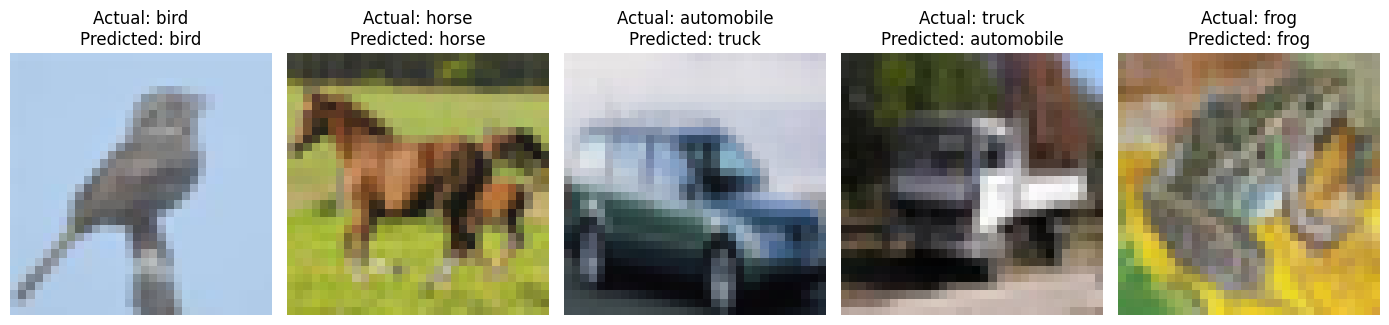

In [50]:
# Step 9: Show five examples
plt.figure(figsize=(14, 4))
for i in range(5):
    image = X_test[i].reshape(image_shape)
    plt.subplot(1, 5, i + 1)
    plt.imshow(image)
    plt.title(
        f"Actual: {class_names[int(y_test[i])]}\n"
        f"Predicted: {class_names[int(y_pred[i])]}"
    )
    plt.axis("off")
plt.tight_layout()
plt.show()